# Diagnóstico de overfitting/underfitting - TronSentinel

**Autores:** Madheline Katerine Torres Hallo y Carlos Vladimir Ramírez Espinoza  
**Modelo:** `tronsentinel-onchain-riskset-v0.6.1-20260928`

Este notebook analiza la capacidad de generalización del clasificador de wallets TRON. Consume los artefactos modulares existentes y **no modifica el modelo desplegado ni utiliza el holdout externo para ajustar hiperparámetros**.


## 1. Configuración y carga

El dataset fue construido punto-en-tiempo con una ventana de 90 días. La separación es cronológica y agrupada por `matchedCaseId`, evitando que controles asociados a un caso aparezcan en particiones diferentes.


In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd() if (Path.cwd() / 'functions').exists() else Path.cwd().parent
DATA_ROOT = REPO_ROOT.parent / 'TronSentinel-data'
DATASET = DATA_ROOT / 'onchain-risk-set-v6-development-dataset/onchain-feature-dataset.csv'
MANIFEST = DATA_ROOT / 'onchain-risk-set-v6-development-dataset/onchain-feature-manifest.json'
OUTPUT_DIR = REPO_ROOT / 'results/reports/overfitting'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO_ROOT / 'functions/scripts'))
from diagnose_overfitting import (
    BalancedGradientBoostingClassifier,
    compare_strategies,
    depth_validation_curve,
    group_learning_curve,
    load_development_dataset,
    quantitative_diagnosis,
    save_tracking_plots,
    split_arrays,
    staged_tracking,
)

frame, manifest, feature_names = load_development_dataset(DATASET, MANIFEST)
splits = split_arrays(frame, feature_names)
print('Filas:', len(frame))
print('Variables:', len(feature_names))
print('Grupos:', frame['matchedCaseId'].nunique())
display(frame['datasetSplit'].value_counts().to_frame('filas'))

Filas: 1854
Variables: 38
Grupos: 400


,filas
datasetSplit,
train,1294
test,282
validation,278


## 2. Exploración del dataset

Se revisan las clases por partición, prevalencia muestral, duplicados, valores nulos y separación de grupos. La prevalencia corresponde al diseño caso-control y no representa prevalencia de producción.


In [2]:
summary = frame.groupby('datasetSplit')['target'].agg(['count', 'sum'])
summary = summary.rename(columns={'count': 'filas', 'sum': 'positivas'})
summary['controles'] = summary['filas'] - summary['positivas']
summary['prevalencia_muestral'] = summary['positivas'] / summary['filas']
display(summary)

integrity = {
    'cohortId_duplicados': int(frame['cohortId'].duplicated().sum()),
    'direcciones_positivas_controles_superpuestas': len(
        set(frame.loc[frame.target.eq(1), 'address']) & set(frame.loc[frame.target.eq(0), 'address'])
    ),
    'nulos_en_features': int(frame[feature_names].isna().sum().sum()),
    'grupos_que_cruzan_splits': int((frame.groupby('matchedCaseId')['datasetSplit'].nunique() > 1).sum()),
}
integrity

,filas,positivas,controles,prevalencia_muestral
datasetSplit,,,,
test,282,60,222,0.212766
train,1294,280,1014,0.216383
validation,278,60,218,0.215827


{'cohortId_duplicados': 0,
 'direcciones_positivas_controles_superpuestas': 0,
 'nulos_en_features': 0,
 'grupos_que_cruzan_splits': 0}

## 3. Tracking durante el entrenamiento

El modelo final se entrena una sola vez sobre `train`. Mediante `staged_predict_proba` se registra log loss, ROC-AUC y PR-AUC después de cada estimador para entrenamiento y validación.


In [3]:
final_model = BalancedGradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.04,
    max_depth=1,
    min_samples_leaf=20,
    subsample=0.8,
    random_state=20260927,
)
final_model.fit(splits['train']['x'], splits['train']['y'])
tracking = staged_tracking(final_model, splits)
tracking.to_csv(OUTPUT_DIR / 'tracking_metrics.csv', index=False)
best_iteration = save_tracking_plots(tracking, OUTPUT_DIR)
print('Mejor iteración según validation log loss:', best_iteration)
display(tracking.iloc[[0, best_iteration - 1, len(tracking) - 1]])

Mejor iteración según validation log loss: 150


,iteration,train_rocAuc,train_prAuc,train_brier,train_logLoss,validation_rocAuc,validation_prAuc,validation_brier,validation_logLoss
0,1,0.832699,0.551798,0.240862,0.674868,0.837844,0.519453,0.24165,0.676444
149,150,0.976085,0.929112,0.065238,0.227013,0.981422,0.934959,0.07574,0.257710
149,150,0.976085,0.929112,0.065238,0.227013,0.981422,0.934959,0.07574,0.257710


### Curvas básicas requeridas

Los archivos `train_validation_loss.png` y `train_validation_scores.png` se generan a 300 DPI. Un gap creciente acompañado por deterioro de la pérdida de validación indicaría overfitting.


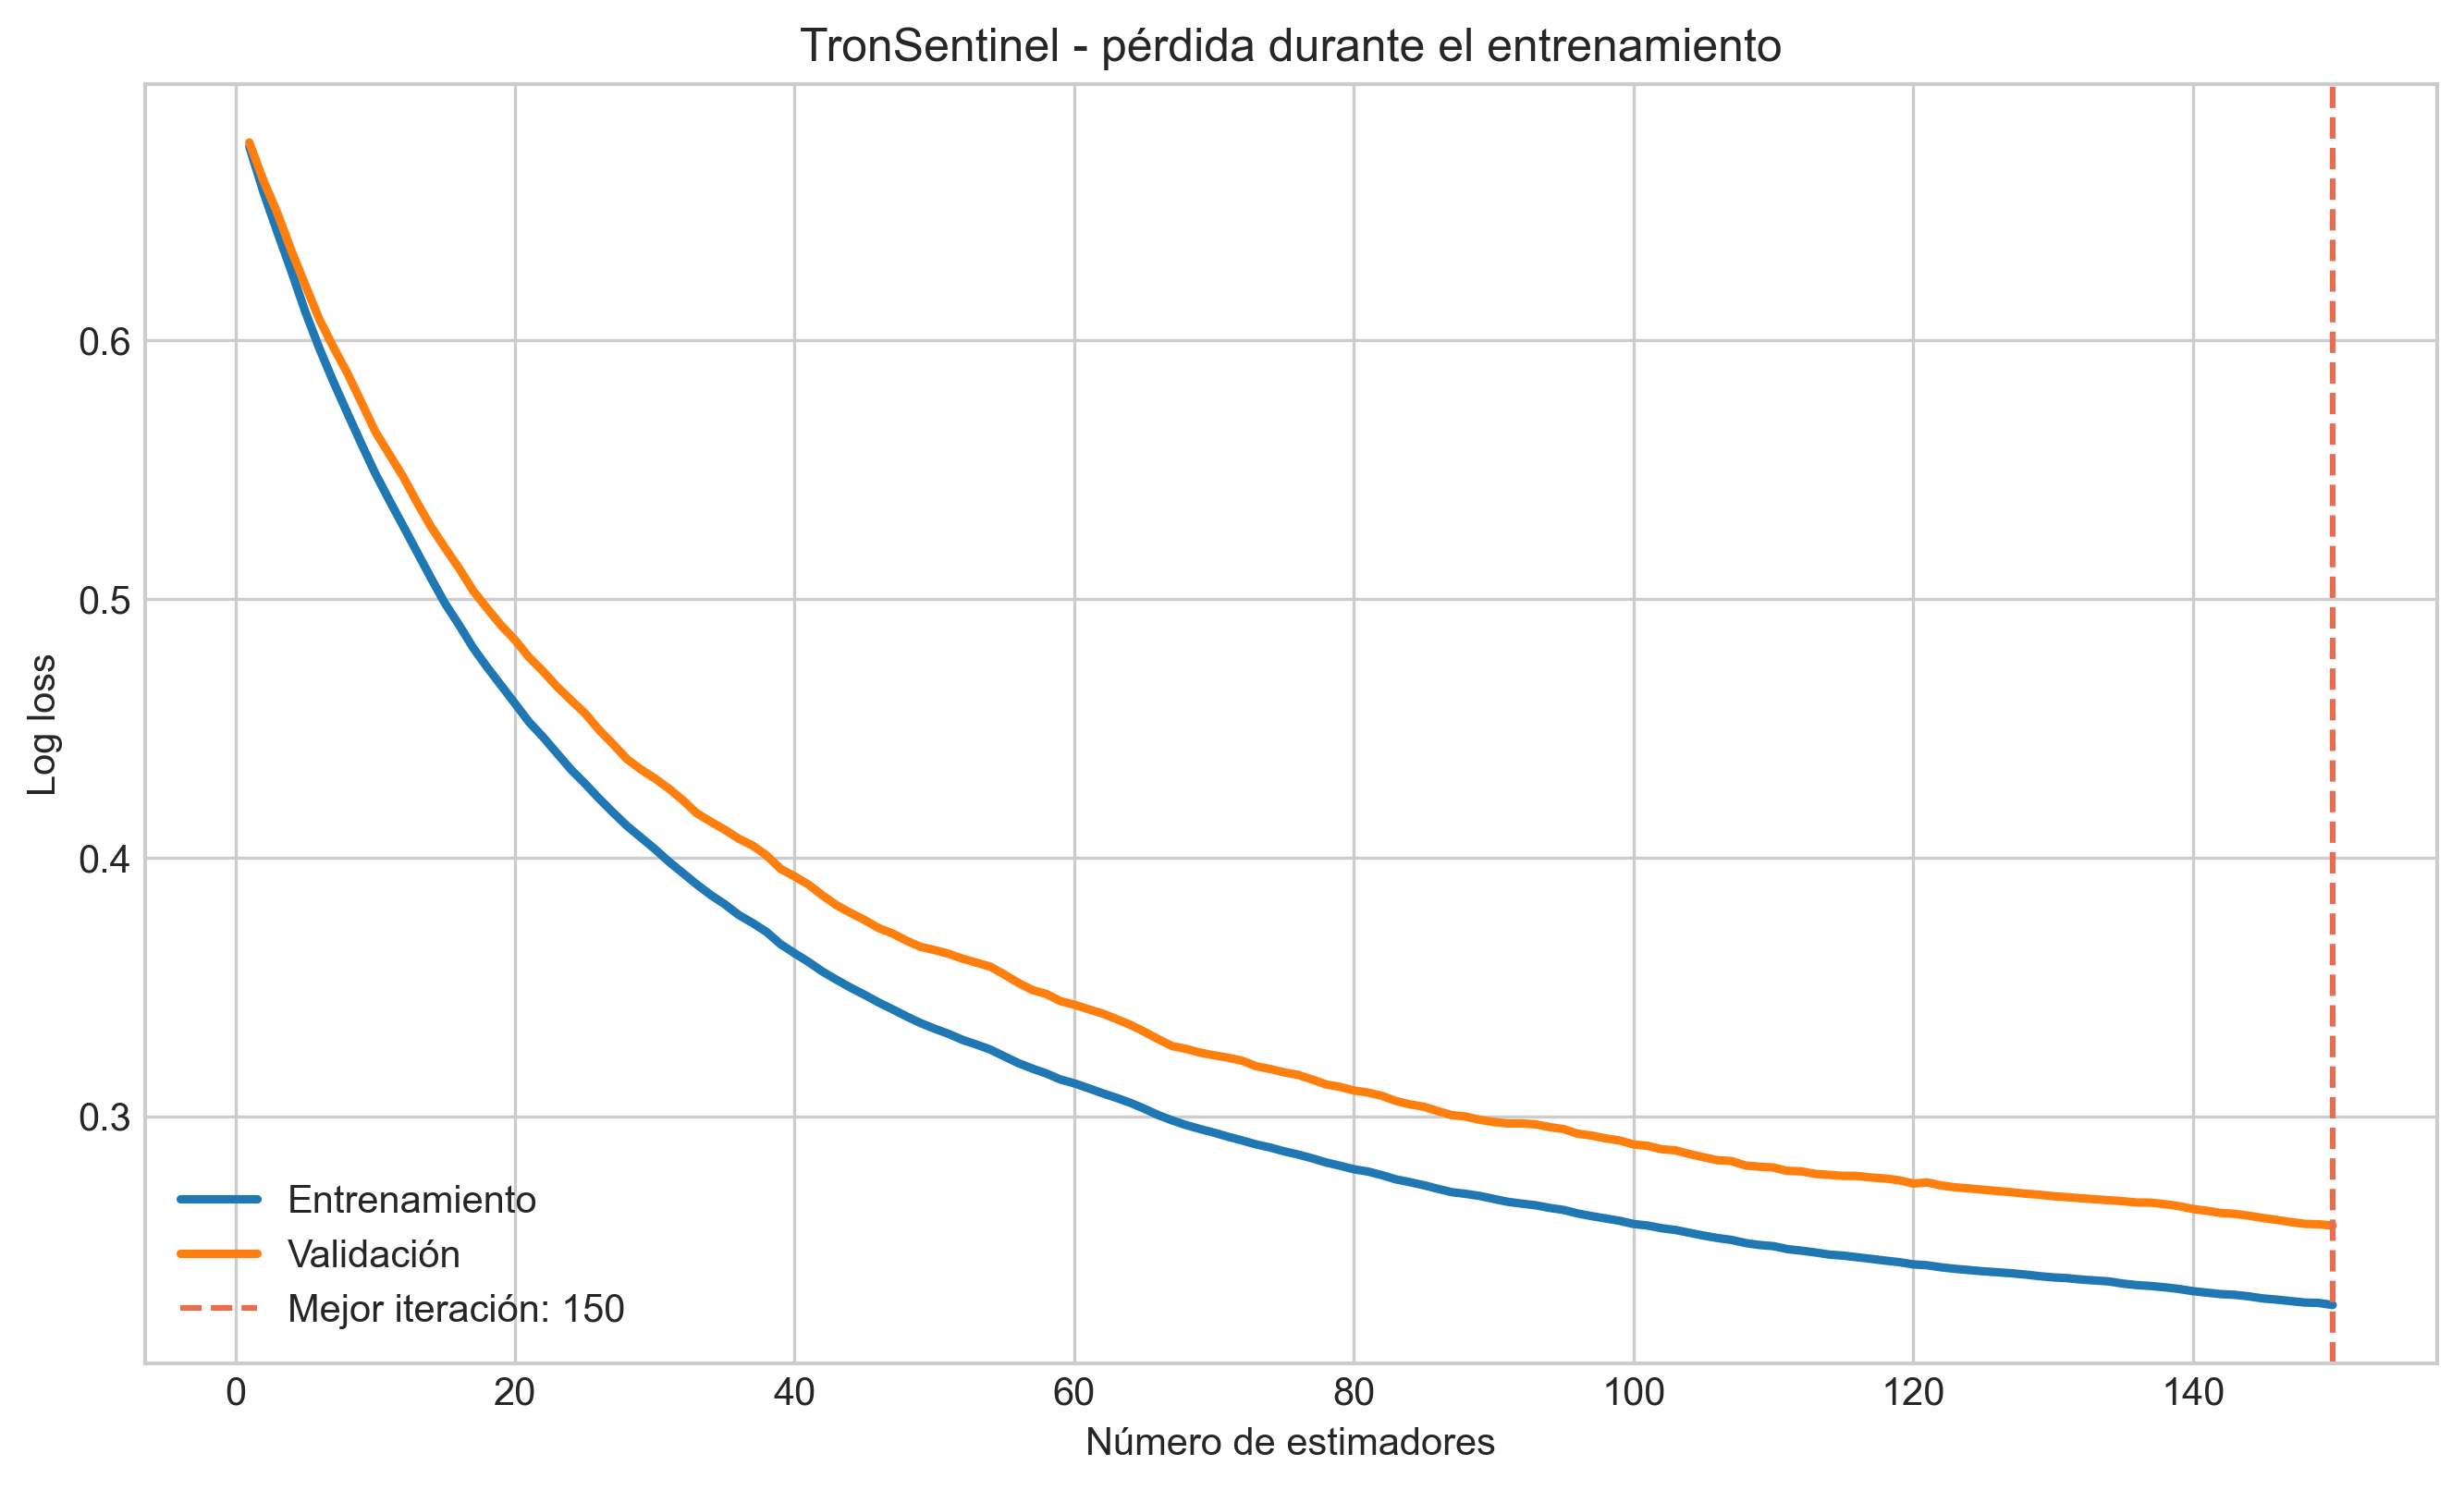

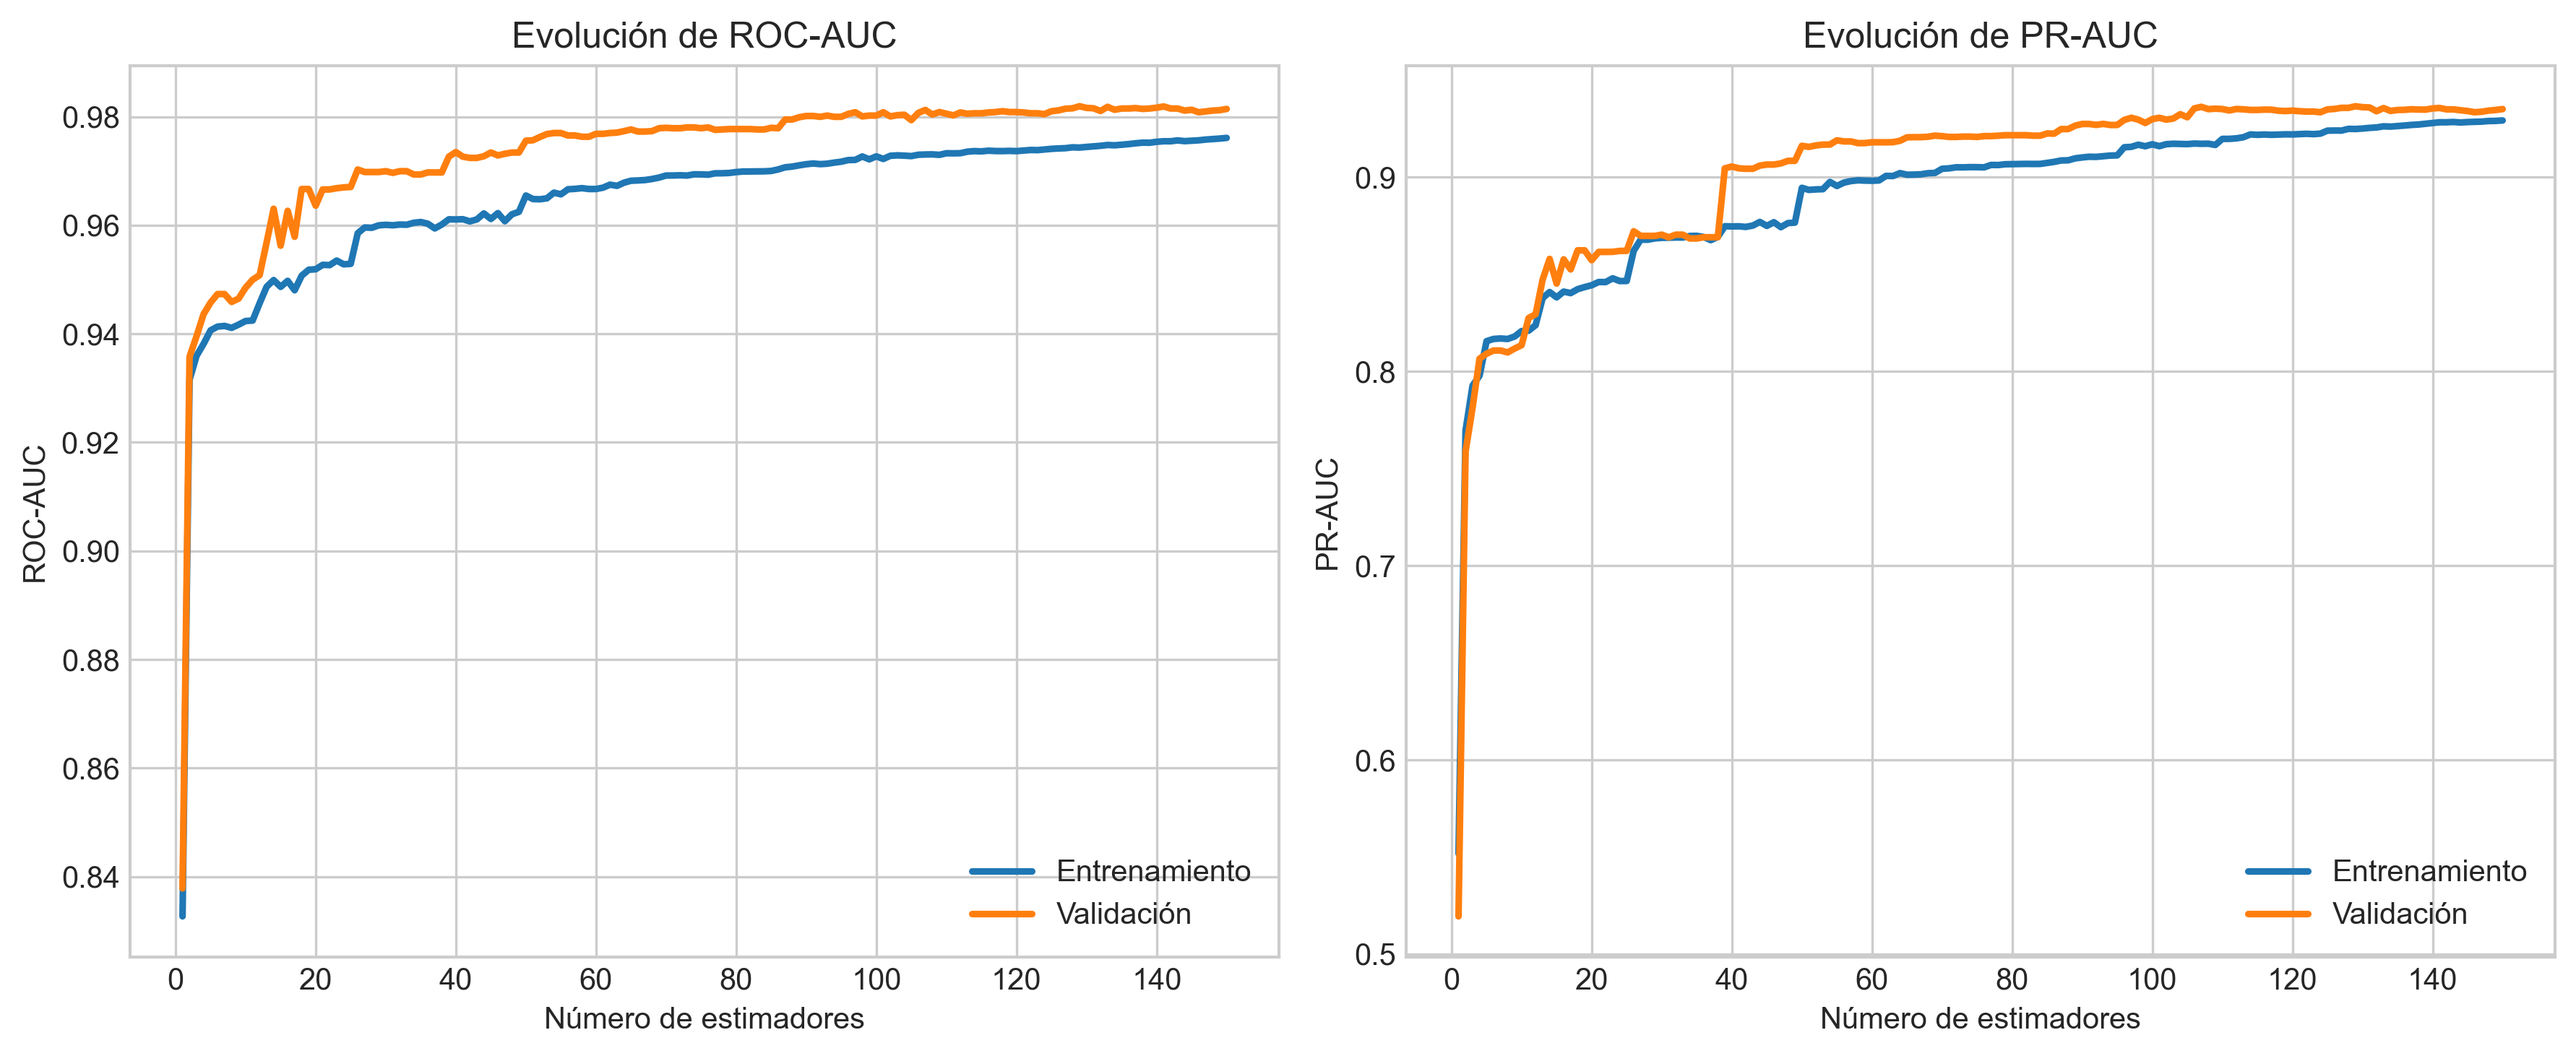

In [4]:
from IPython.display import Image, display
display(Image(filename=str(OUTPUT_DIR / 'train_validation_loss.png')))
display(Image(filename=str(OUTPUT_DIR / 'train_validation_scores.png')))

## 4. Learning curve por tamaño del dataset

Se utiliza `learning_curve` con `GroupKFold`, manteniendo unidos los registros con el mismo `matchedCaseId`. La métrica principal es PR-AUC por ser más informativa que accuracy en datos desbalanceados.


,trainSize,trainMean,trainStd,validationMean,validationStd
0,251,0.982313,0.005878,0.901633,0.039101
1,502,0.967598,0.006021,0.905178,0.033865
2,754,0.933981,0.008148,0.910058,0.033150
3,1005,0.930117,0.007708,0.908234,0.033968
4,1257,0.933420,0.005220,0.917392,0.027751


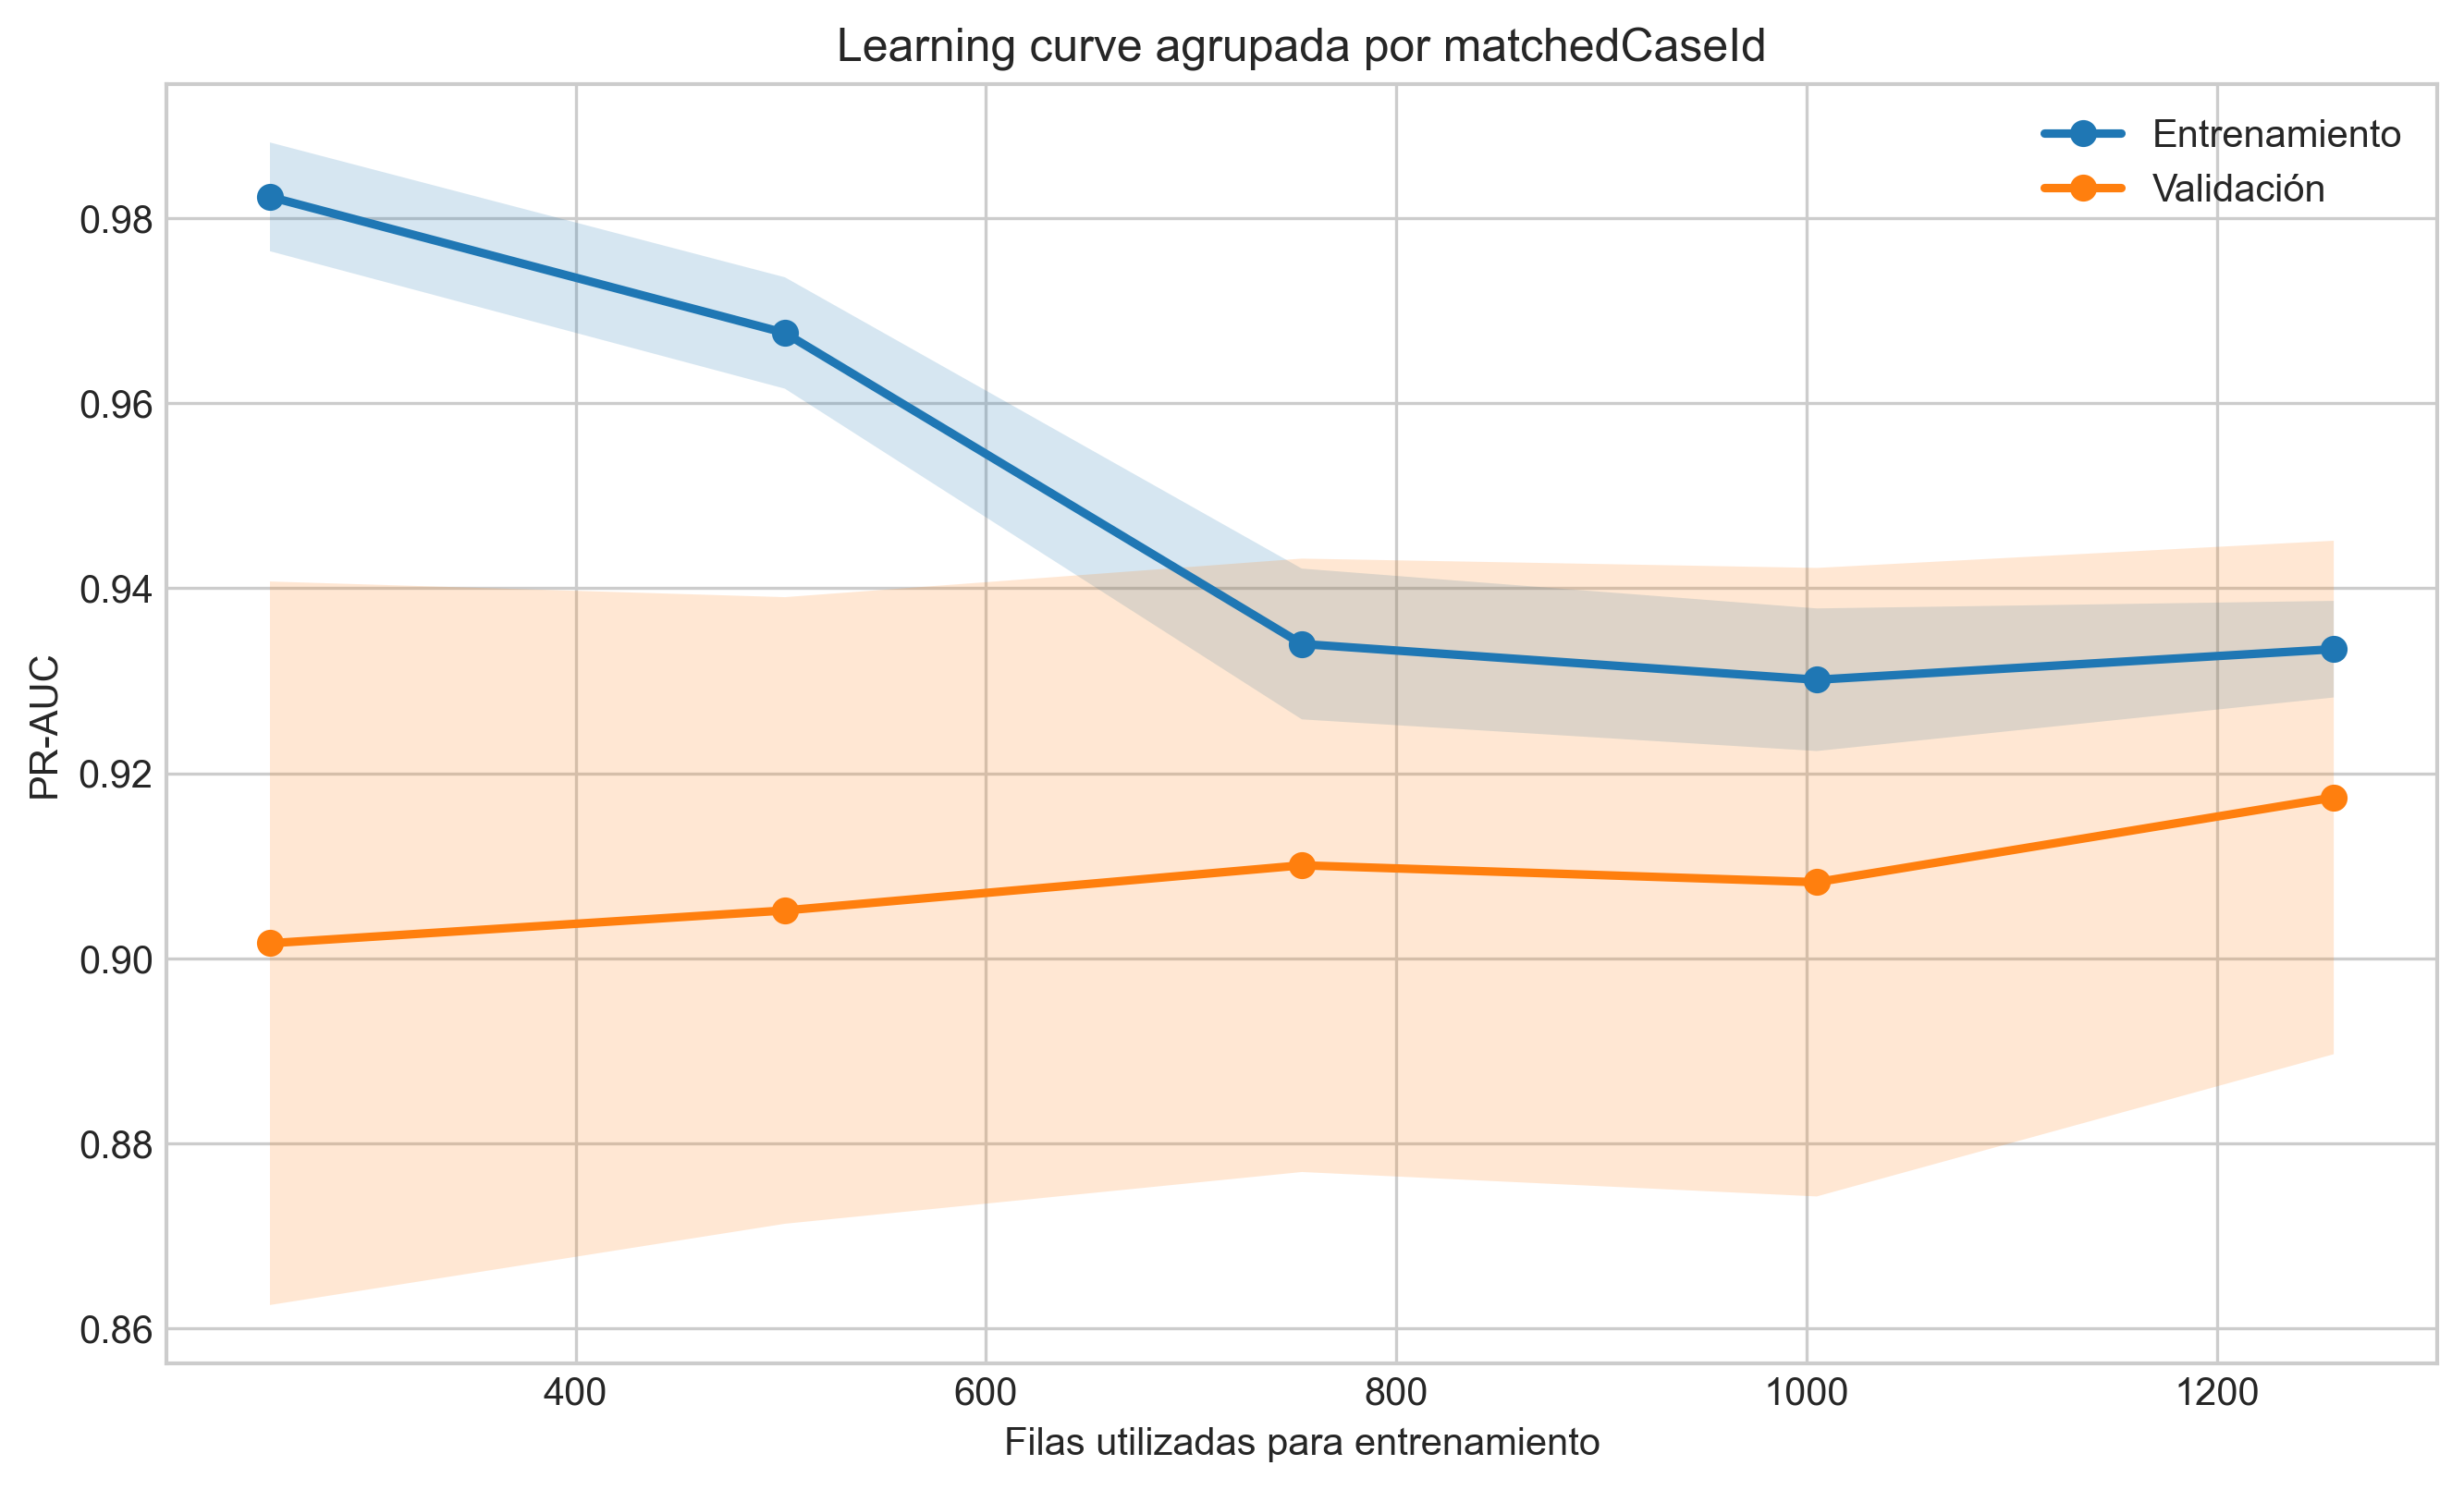

In [5]:
learning_results = group_learning_curve(frame, feature_names, OUTPUT_DIR)
display(learning_results)
display(Image(filename=str(OUTPUT_DIR / 'learning_curve_pr_auc.png')))

## 5. Validation curve por complejidad

Se evalúa `max_depth` entre 1 y 4. Si el score de entrenamiento aumenta mientras validación se estanca o disminuye, el incremento de profundidad está produciendo overfitting.


,maxDepth,trainMean,trainStd,validationMean,validationStd
0,1,0.933922,0.004786,0.915451,0.027192
1,2,0.958716,0.003462,0.918809,0.025534
2,3,0.979542,0.001905,0.922298,0.024682
3,4,0.990992,0.001030,0.927093,0.019290


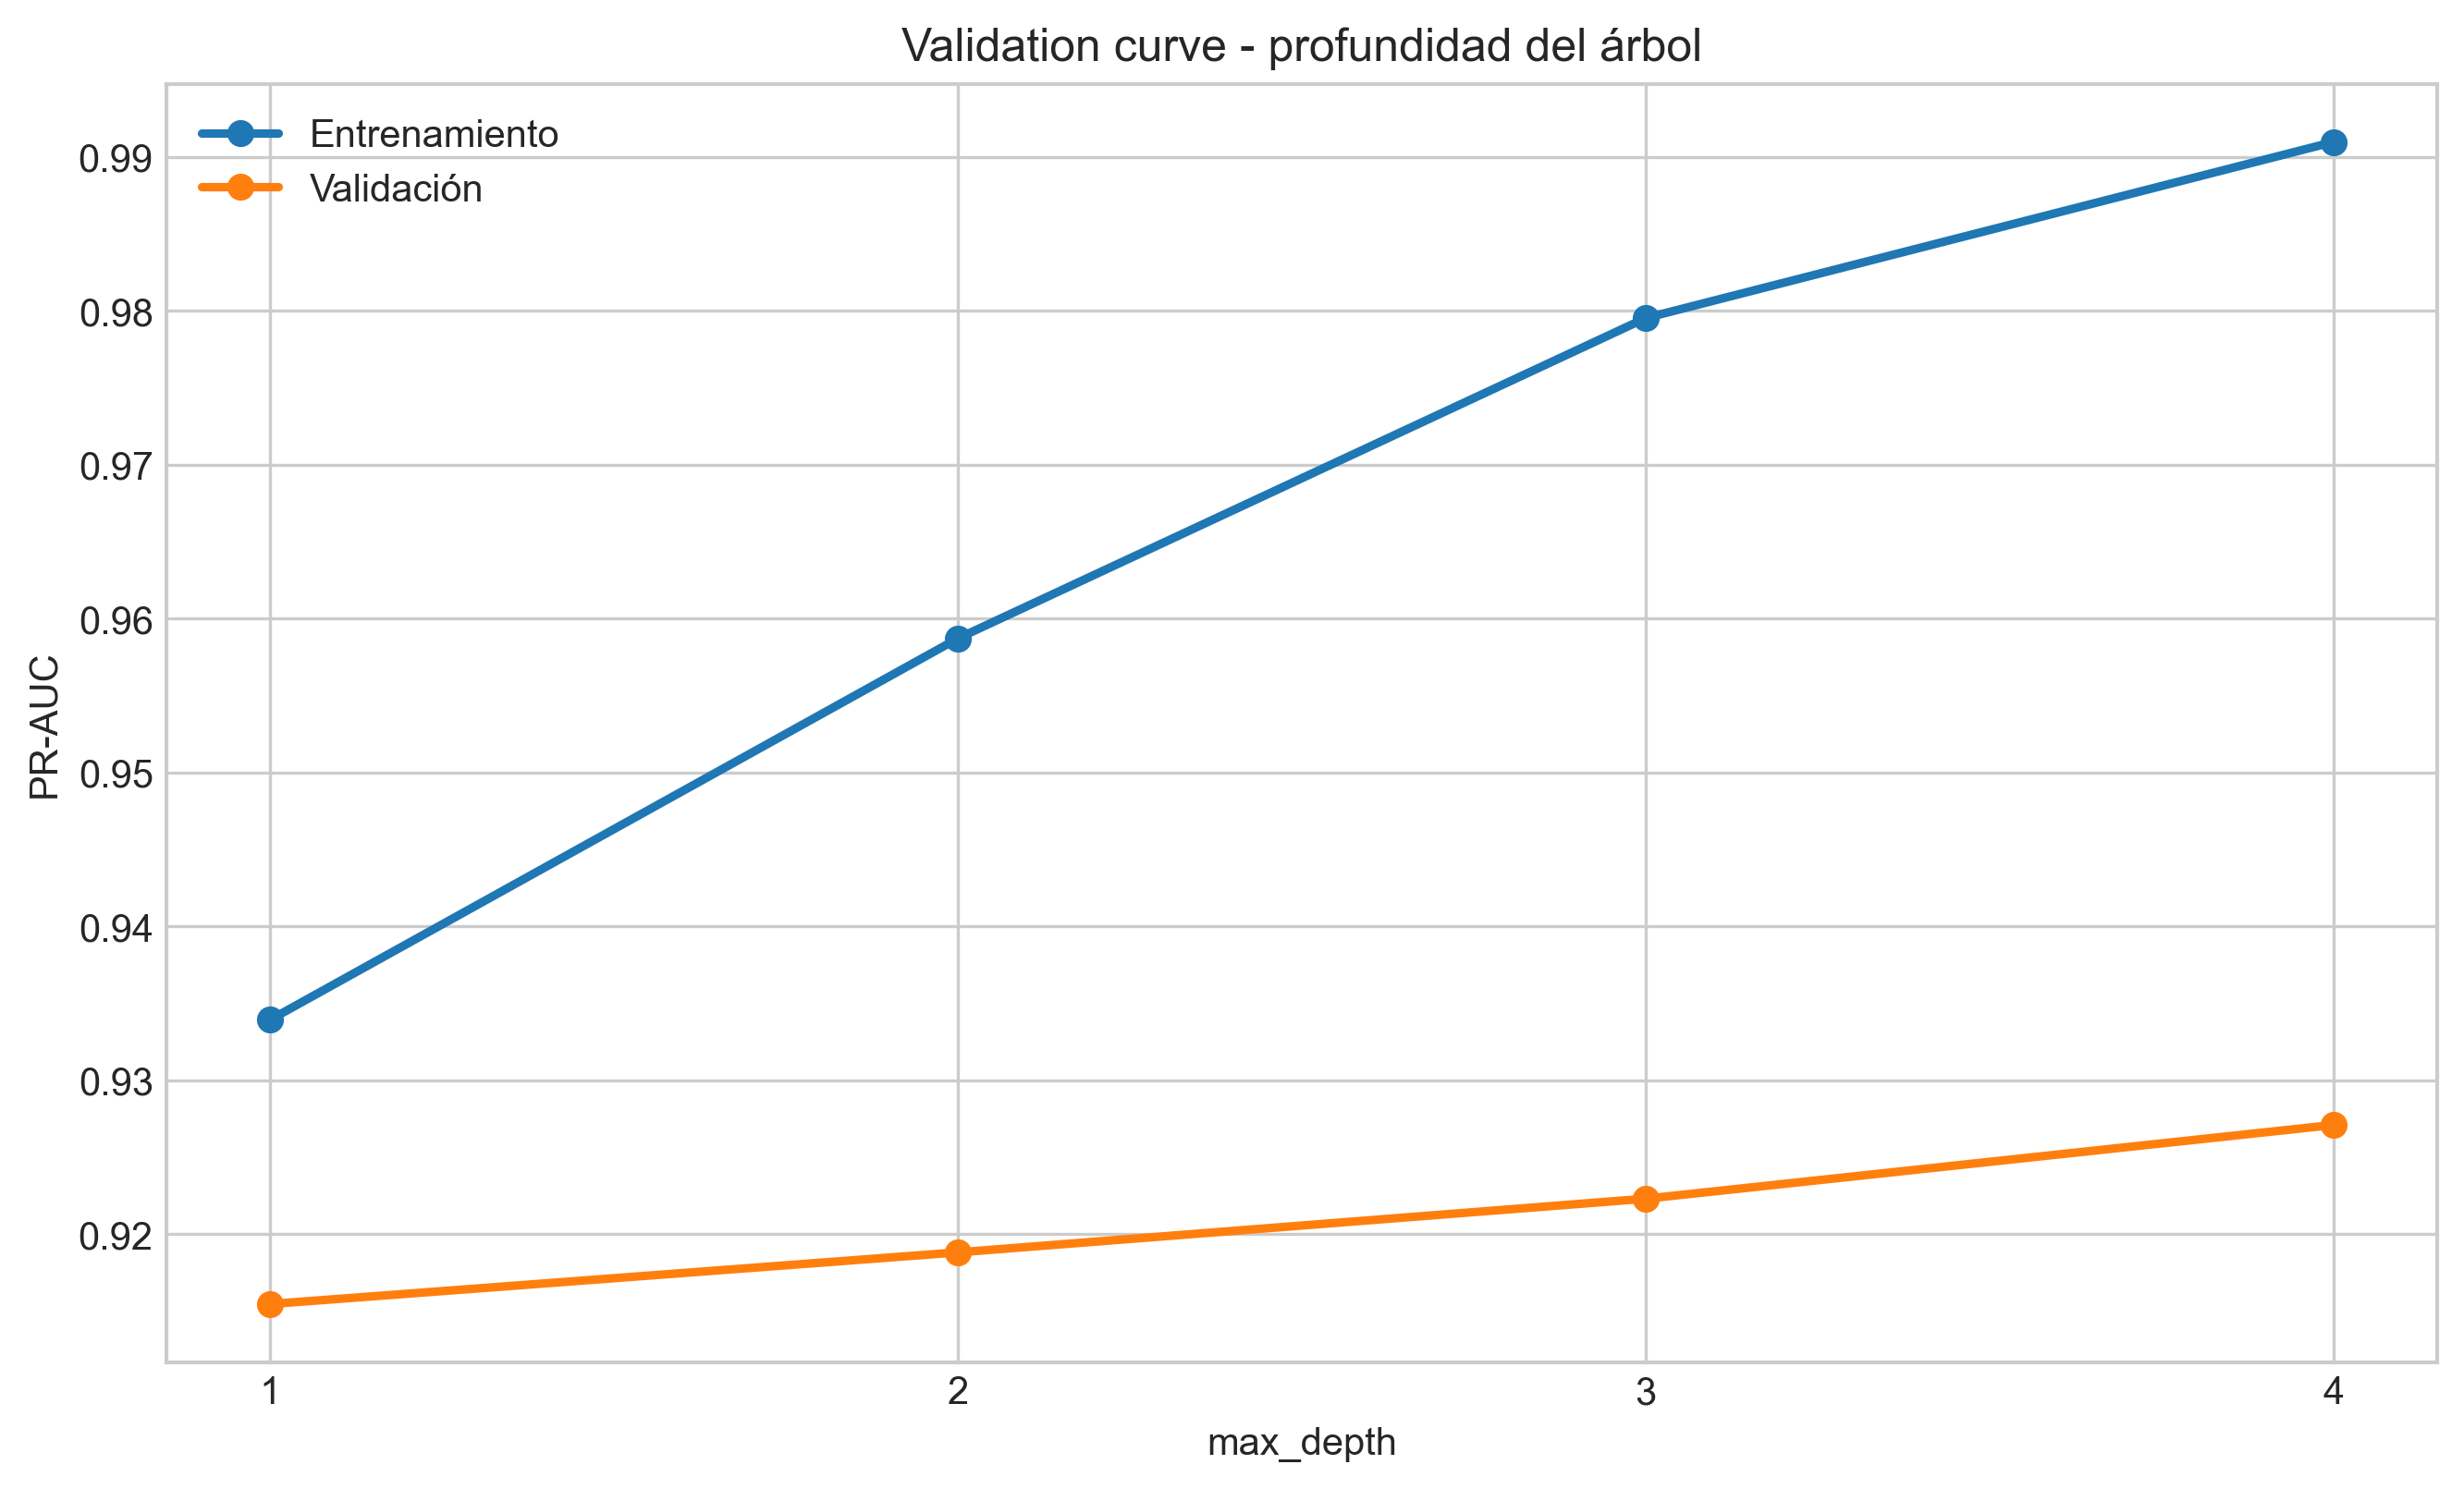

In [6]:
depth_results = depth_validation_curve(frame, feature_names, OUTPUT_DIR)
display(depth_results)
display(Image(filename=str(OUTPUT_DIR / 'validation_curve_depth.png')))

## 6. Dos estrategias de mejora

1. **Reducción de complejidad:** árboles de profundidad 3 a stumps de profundidad 1.
2. **Regularización adicional:** `min_samples_leaf=20` y `subsample=0.8`.

Las estrategias se comparan con las mismas particiones congeladas. El holdout externo no participa.


,strategy,max_depth,min_samples_leaf,subsample,train_prAuc,validation_prAuc,test_prAuc,prAucGapTrainValidation,prAucGapTrainTest
0,Base compleja,3,1,1.0,0.985447,0.949586,0.873530,0.035860,0.111917
1,Estrategia 1 - menor complejidad,1,1,1.0,0.927918,0.942099,0.876916,-0.014181,0.051002
2,Estrategia 2 - modelo regularizado,1,20,0.8,0.929112,0.934959,0.898662,-0.005847,0.030450


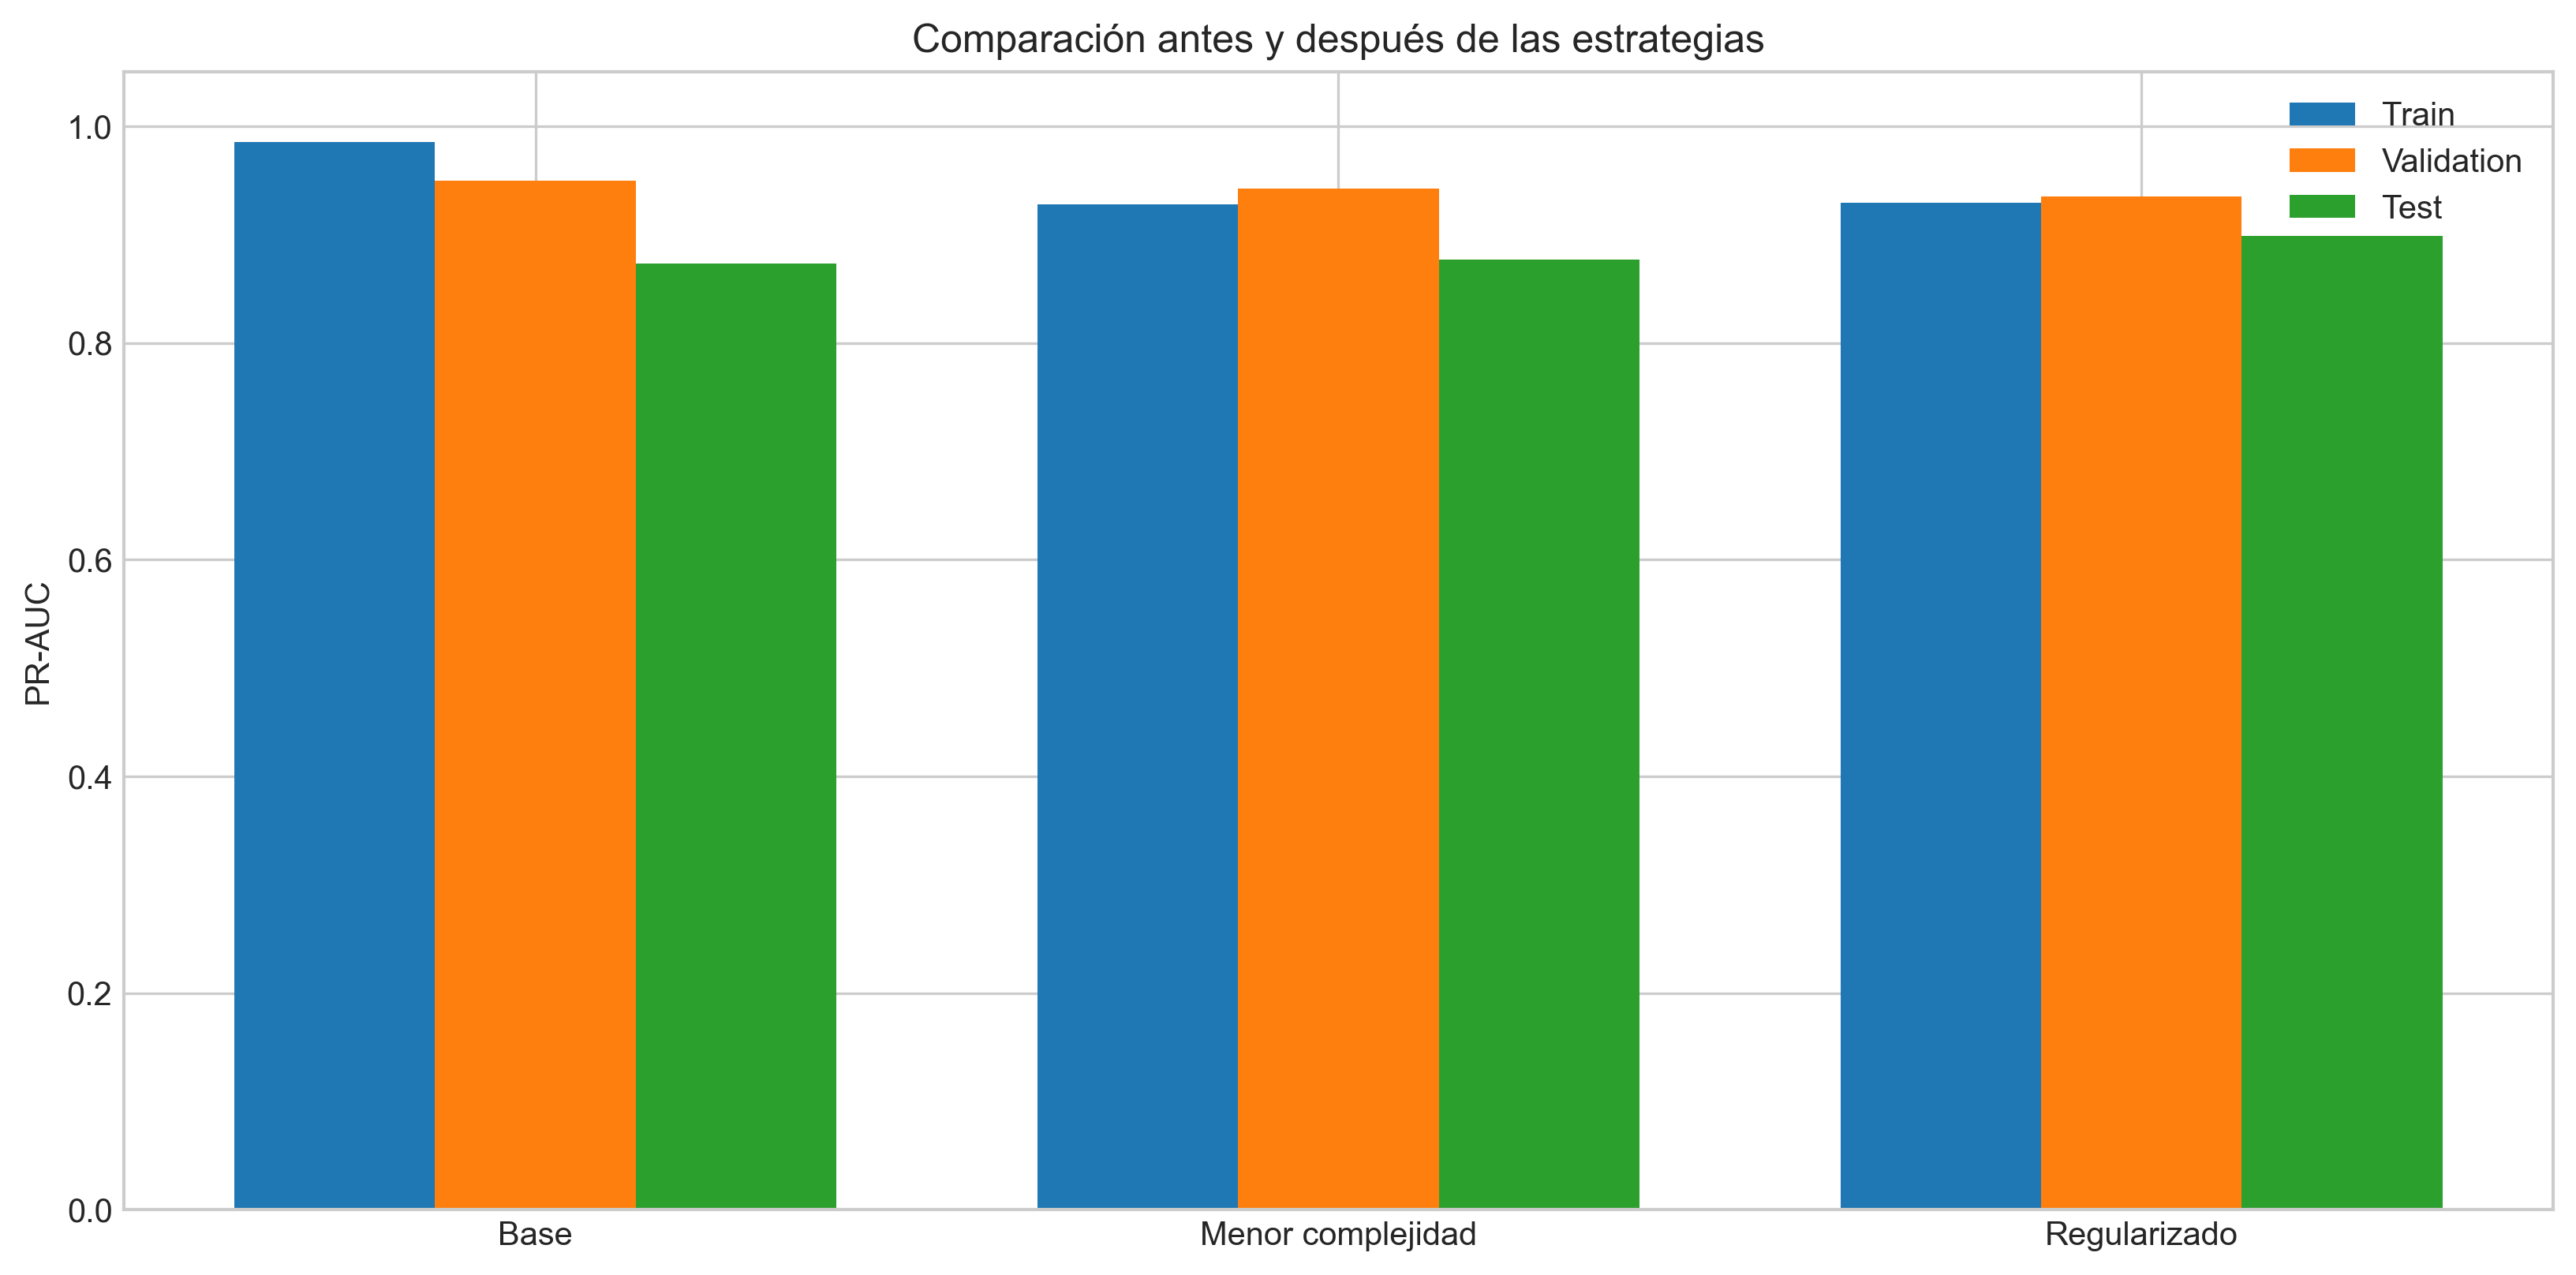

In [7]:
strategies = compare_strategies(splits, OUTPUT_DIR)
columns = [
    'strategy', 'max_depth', 'min_samples_leaf', 'subsample',
    'train_prAuc', 'validation_prAuc', 'test_prAuc',
    'prAucGapTrainValidation', 'prAucGapTrainTest',
]
display(strategies[columns])
display(Image(filename=str(OUTPUT_DIR / 'strategies_comparison.png')))

## 7. Diagnóstico cuantitativo

La regla orientativa combina el gap de PR-AUC y el gap de log loss. La conclusión final debe interpretar conjuntamente las curvas, métricas y estabilidad entre particiones.


In [8]:
diagnosis = quantitative_diagnosis(tracking, strategies)
(OUTPUT_DIR / 'diagnosis.json').write_text(
    json.dumps(diagnosis, indent=2, ensure_ascii=False) + '\n', encoding='utf-8'
)
display(diagnosis)

{'diagnosis': 'GENERALIZACION_ADECUADA',
 'bestIterationByValidationLogLoss': 150,
 'trainValidationPrAucGap': -0.005846589169088867,
 'trainValidationLogLossGapAtBestIteration': 0.03069681817739006,
 'validationPrAuc': 0.9349587282029832,
 'testPrAuc': 0.8986624427613512,
 'note': 'Regla académica orientativa; la interpretación final debe considerar todas las curvas.'}

## 8. Conclusiones y reflexiones

Complete esta sección después de ejecutar todas las celdas:

- Comportamiento observado en train y validation loss.
- Evolución de ROC-AUC y PR-AUC.
- Efecto del tamaño del dataset.
- Profundidad a partir de la cual aparece un gap de generalización.
- Resultado de las dos estrategias implementadas.
- Diagnóstico final: overfitting, underfitting o generalización adecuada.
- Recomendaciones futuras sin utilizar el holdout externo para ajustar el modelo.

### Evidencia previa del proyecto

El modelo congelado alcanzó ROC-AUC 0,967 y PR-AUC 0,899 en test interno. En el holdout externo de una sola apertura obtuvo ROC-AUC 0,962 y PR-AUC 0,929. Estos resultados externos se citan como confirmación posterior, no como datos para seleccionar hiperparámetros.


## 9. Referencias técnicas

- Friedman, J. H. (2001). Greedy Function Approximation: A Gradient Boosting Machine.
- Scikit-learn: `GradientBoostingClassifier`, `learning_curve` y `validation_curve`.
- Saito, T. y Rehmsmeier, M. (2015). The Precision-Recall Plot Is More Informative than the ROC Plot for Imbalanced Datasets.
- Brier, G. W. (1950). Verification of Forecasts Expressed in Terms of Probability.
